# Klasifikasi Soal LeetCode: Tingkat Kesulitan dan Topik

Acaryanandana Alif Fajar, 3325600031, 5STr-SDT B

Eksperimen untuk paper. Masukannya dua dataset dari `Tugas/02_Penyiapan_Dataset.ipynb`.

| | Target | Sifat | Soal |
|---|---|---|---|
| Dataset I | Difficulty | single-label, 3 kelas | 3.284 |
| Dataset II | Category | multi-label, 23 label | 3.094 |

Empat representasi teks dibandingkan, yaitu Bag of Words, TF-IDF, N-gram, dan word
embedding, masing masing dipasangkan dengan enam algoritma klasifikasi.

## Persiapan

In [1]:
import collections
import re
import ssl
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, hamming_loss, precision_score, recall_score)
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
try:
    import certifi
    ssl._create_default_https_context = (
        lambda *a, **kw: ssl.create_default_context(cafile=certifi.where()))
except ImportError:
    ssl._create_default_https_context = ssl._create_unverified_context
for paket in ("punkt", "punkt_tab", "stopwords", "wordnet"):
    nltk.download(paket, quiet=True)

ROOT = Path.cwd().parent if Path.cwd().name == "Paper" else Path.cwd()
HASIL = ROOT / "Dataset" / "paper"
GAMBAR = HASIL / "gambar"
GAMBAR.mkdir(parents=True, exist_ok=True)

SEED, LIPATAN, PORSI_UJI = 42, 5, 0.2
DIMENSI, MIN_COUNT, JENDELA, NEGATIF, EPOCH = 100, 5, 5, 5, 10
SURFACE, TEKS_UTAMA, TEKS_SEKUNDER, GARIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"

import platform, sys
print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy       :", np.__version__, "  pandas:", pd.__version__, "  NLTK:", nltk.__version__)
print("Perangkat   :", platform.system(), platform.machine())

Python      : 3.14.5
scikit-learn: 1.9.1
NumPy       : 2.5.2   pandas: 3.0.5   NLTK: 3.10.3
Perangkat   : Darwin arm64


**Penjelasan.** Seluruh angka acak dikunci ke 42. Word2Vec dilatih 10 epoch dengan ambang kemunculan 5,
lebih rendah dari percobaan sebelumnya karena korpusnya kini 14 kali lebih besar sehingga
tiap epoch sudah melihat jauh lebih banyak contoh.

## Memuat Dua Dataset

In [2]:
ds1 = pd.read_csv(HASIL / "dataset1_difficulty.csv")
ds2 = pd.read_csv(HASIL / "dataset2_category.csv")
ds2["Category"] = ds2["Category"].apply(lambda s: [t.strip() for t in s.split(",")])

mlb = MultiLabelBinarizer()
Y2 = mlb.fit_transform(ds2["Category"])
LABEL = list(mlb.classes_)

print("Dataset I  :", f"{len(ds1):,} soal, target Difficulty,", ds1["Difficulty"].nunique(), "kelas")
for kelas, n in ds1["Difficulty"].value_counts().items():
    print(f"   {kelas:<8} {n:>5}  ({100 * n / len(ds1):>4.1f} persen)")

print("\nDataset II :", f"{len(ds2):,} soal, target Category,", len(LABEL), "label")
print("   matriks label  :", Y2.shape)
print("   rata rata label:", f"{Y2.sum(axis=1).mean():.2f} per soal")
print("   label tersering:", LABEL[int(Y2.sum(axis=0).argmax())], f"({Y2.sum(axis=0).max():,} soal)")
print("   label terjarang:", LABEL[int(Y2.sum(axis=0).argmin())], f"({Y2.sum(axis=0).min():,} soal)")

Dataset I  : 3,284 soal, target Difficulty, 3 kelas
   Medium    1660  (50.5 persen)
   Easy       839  (25.5 persen)
   Hard       785  (23.9 persen)

Dataset II : 3,094 soal, target Category, 23 label
   matriks label  : (3094, 23)
   rata rata label: 2.85 per soal
   label tersering: Array (1,947 soal)
   label terjarang: Binary Tree (131 soal)


**Penjelasan.** `MultiLabelBinarizer` mengubah daftar label tiap soal jadi matriks biner berukuran jumlah
soal kali 23. Baris yang punya lebih dari satu angka satu berarti soal itu memang membawa
beberapa topik sekaligus, dan bentuk inilah yang dipertahankan. Topik sengaja tidak
diringkas jadi satu label karena hal itu akan membuang sifat multi-label yang justru
menjadi ciri data ini.

## Preprocessing Teks

In [3]:
STOPWORD_LEETCODE = {
    "example", "input", "output", "explanation", "constraint", "constraints",
    "given", "return", "returns", "true", "false", "null",
}
lemmatizer = WordNetLemmatizer()
daftar_stopword = set(stopwords.words("english")) | STOPWORD_LEETCODE


def bersihkan_teks(teks):
    teks = re.sub(r"[^a-z\s]", "", str(teks).lower())
    kata = [k for k in word_tokenize(teks) if k not in daftar_stopword]
    return " ".join(lemmatizer.lemmatize(k) for k in kata)


mulai = time.time()
ds1["clean"] = ds1["Description"].apply(bersihkan_teks)
peta = dict(zip(ds1["Problem ID"], ds1["clean"]))
ds2["clean"] = ds2["Problem ID"].map(peta)
ds2 = ds2.dropna(subset=["clean"]).reset_index(drop=True)
Y2 = mlb.transform(ds2["Category"])

token = [k for t in ds1["clean"] for k in t.split()]
susut = 100 * (1 - ds1["clean"].str.len().mean() / ds1["Description"].str.len().mean())

print("Waktu preprocessing:", f"{time.time() - mulai:.0f} detik")
print("Stopword khas LeetCode:", len(STOPWORD_LEETCODE))
print("Panjang rata rata :", f"{ds1['Description'].str.len().mean():.0f} menjadi "
      f"{ds1['clean'].str.len().mean():.0f} karakter, susut {susut:.0f} persen")
print("Total token       :", f"{len(token):,}")
print("Kata unik         :", f"{len(set(token)):,}")
print("\nSEBELUM:", ds1["Description"][0][:140], "...")
print("SESUDAH:", ds1["clean"][0][:140], "...")

pd.DataFrame({"stage": ["Raw", "Preprocessed"],
              "text": [ds1["Description"][0][:180], ds1["clean"][0][:180]]}
             ).to_csv(HASIL / "tabel_contoh_preprocessing.csv", index=False)

Waktu preprocessing: 5 detik
Stopword khas LeetCode: 12
Panjang rata rata : 1222 menjadi 566 karakter, susut 54 persen
Total token       : 275,745
Kata unik         : 11,257

SEBELUM: You are given an array of integers nums and an integer target , return indices of the two numbers such that they add up to target . You may  ...
SESUDAH: array integer nums integer target index two number add target may assume would exactly one solution may use element twice answer order nums  ...


**Penjelasan.** Lima langkah dijalankan berurutan: case folding, cleansing, tokenizing, stopword removal,
dan lemmatization. Teks dibersihkan sekali lalu dipetakan ke Dataset II lewat Problem ID,
supaya kedua dataset memakai hasil preprocessing yang persis sama. Dua belas stopword khas
LeetCode ditambahkan karena kata seperti `example` dan `constraint` ada di hampir semua
soal sehingga tidak membedakan apa pun.

## Empat Representasi Teks

In [4]:
PARAM_BOW = dict(min_df=2, max_df=0.85)
PARAM_TFIDF = dict(min_df=2, max_df=0.85, sublinear_tf=True)
PARAM_NGRAM = dict(ngram_range=(1, 2), min_df=3, max_df=0.85, sublinear_tf=True)

for nama, V in (("Bag of Words", CountVectorizer(**PARAM_BOW)),
                ("TF-IDF", TfidfVectorizer(**PARAM_TFIDF)),
                ("N-gram (1,2)", TfidfVectorizer(**PARAM_NGRAM))):
    X = V.fit_transform(ds1["clean"])
    jarang = 100 * (1 - X.nnz / np.prod(X.shape))
    print(f"{nama:<14} {X.shape[1]:>7,} fitur   kejarangan {jarang:.1f} persen")

Bag of Words     4,131 fitur   kejarangan 99.2 persen


TF-IDF           4,131 fitur   kejarangan 99.2 persen


N-gram (1,2)    12,970 fitur   kejarangan 99.6 persen


**Penjelasan.** Tiga representasi jarang dibangun dari teks yang sama. Bag of Words hanya menghitung
kemunculan kata. TF-IDF menimbang hitungan itu dengan logaritma kebalikan jumlah dokumen
yang memuatnya, dan `sublinear_tf` memakai `1 + log(tf)` supaya kata yang muncul dua puluh
kali tidak dianggap dua puluh kali lebih penting. N-gram menambahkan pasangan kata
berurutan sehingga `binary tree` terbaca satu fitur, dengan `min_df=3` karena jumlah
fiturnya melonjak. Ukuran di sini hanya untuk gambaran, karena saat evaluasi semua
vectorizer dilatih ulang di dalam tiap lipatan.

## Pelatihan Word Embedding

In [5]:
def latih_word2vec(korpus_indeks, jumlah_kata, peluang_negatif, dimensi, jendela,
                   negatif, epoch, lr_awal=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    W_in = rng.normal(0, 0.1, (jumlah_kata, dimensi))
    W_out = np.zeros((jumlah_kata, dimensi))
    sigmoid = lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -6, 6)))

    mulai = time.time()
    for ep in range(epoch):
        lr = lr_awal * (1 - ep / epoch) + 1e-4
        for dokumen in korpus_indeks:
            for i, pusat in enumerate(dokumen):
                radius = rng.integers(1, jendela + 1)
                for j in range(max(0, i - radius), min(len(dokumen), i + radius + 1)):
                    if j == i:
                        continue
                    sampel = np.concatenate(([dokumen[j]],
                                             rng.choice(jumlah_kata, negatif, p=peluang_negatif)))
                    label = np.zeros(negatif + 1)
                    label[0] = 1.0
                    v = W_in[pusat]
                    galat = sigmoid(W_out[sampel] @ v) - label
                    grad_v = galat @ W_out[sampel]
                    W_out[sampel] -= lr * np.outer(galat, v)
                    W_in[pusat] -= lr * grad_v
        print(f"  epoch {ep + 1:>2}/{epoch}  {time.time() - mulai:>5.0f} detik")
    return W_in


korpus = [t.split() for t in ds1["clean"]]
frekuensi = collections.Counter(token)
kosakata = [k for k, n in frekuensi.most_common() if n >= MIN_COUNT]
indeks_kata = {k: i for i, k in enumerate(kosakata)}
korpus_indeks = [[indeks_kata[k] for k in dok if k in indeks_kata] for dok in korpus]
bobot = np.array([frekuensi[k] for k in kosakata], dtype=float) ** 0.75

FILE_W2V = HASIL / "word2vec_3284.npz"
if FILE_W2V.exists() and list(np.load(FILE_W2V, allow_pickle=True)["kosakata"]) == kosakata:
    vektor_kata = np.load(FILE_W2V, allow_pickle=True)["vektor"]
    print("Memakai model tersimpan:", FILE_W2V.name)
else:
    print(f"Melatih Word2Vec: {len(kosakata):,} kata, {DIMENSI} dimensi, {EPOCH} epoch\n")
    W_in = latih_word2vec(korpus_indeks, len(kosakata), bobot / bobot.sum(),
                          DIMENSI, JENDELA, NEGATIF, EPOCH)
    vektor_kata = W_in / (np.linalg.norm(W_in, axis=1, keepdims=True) + 1e-9)
    np.savez(FILE_W2V, vektor=vektor_kata, kosakata=np.array(kosakata, dtype=object))

dikenali = sum(1 for k in token if k in indeks_kata)
print("\nKosakata     :", f"{len(kosakata):,} kata (ambang {MIN_COUNT} kemunculan)")
print("Matriks kata :", vektor_kata.shape)
print("Cakupan token:", f"{100 * dikenali / len(token):.1f} persen")

Melatih Word2Vec: 3,780 kata, 100 dimensi, 10 epoch



  epoch  1/10     82 detik


  epoch  2/10    163 detik


  epoch  3/10    243 detik


  epoch  4/10    329 detik


  epoch  5/10    414 detik


  epoch  6/10    500 detik


  epoch  7/10    590 detik


  epoch  8/10    672 detik


  epoch  9/10    754 detik


  epoch 10/10    834 detik

Kosakata     : 3,780 kata (ambang 5 kemunculan)
Matriks kata : (3780, 100)
Cakupan token: 95.4 persen


**Penjelasan.** Word2Vec ditulis sendiri dengan NumPy karena gensim belum menyediakan paket siap pasang
untuk Python 3.14. Metodenya Skip-gram with Negative Sampling. Berbeda dari tiga
representasi sebelumnya, model ini dilatih sekali pada seluruh korpus dan tidak dilatih
ulang tiap lipatan. Alasannya pelatihan embedding tidak memakai label sama sekali,
sehingga setara dengan memakai embedding terlatih, dan melatih ulang sepuluh kali akan
memakan waktu lebih dari satu setengah jam. Pilihan ini dicatat sebagai keterbatasan.

## Pemeriksaan Kualitas Embedding

In [6]:
def kata_mirip(kata, n=5):
    if kata not in indeks_kata:
        return "tidak ada di kosakata"
    skor = vektor_kata @ vektor_kata[indeks_kata[kata]]
    skor[indeks_kata[kata]] = -9
    return ", ".join(f"{kosakata[i]} ({skor[i]:.2f})" for i in np.argsort(-skor)[:n])


baris_mirip = []
for kata in ("array", "string", "tree", "sorted", "binary", "graph"):
    tetangga = kata_mirip(kata)
    baris_mirip.append({"query": kata, "nearest neighbours": tetangga})
    print(f"{kata:<10} -> {tetangga}")

pd.DataFrame(baris_mirip).to_csv(HASIL / "tabel_kata_mirip.csv", index=False)


def vektor_dokumen(teks_seri):
    baris = []
    for dok in (t.split() for t in teks_seri):
        dipakai = [vektor_kata[indeks_kata[k]] for k in dok if k in indeks_kata]
        baris.append(np.mean(dipakai, axis=0) if dipakai else np.zeros(DIMENSI))
    return np.vstack(baris)


X_embed1 = vektor_dokumen(ds1["clean"])
print("\nMatriks dokumen :", X_embed1.shape)
print("Rentang nilai   :", f"{X_embed1.min():.3f} sampai {X_embed1.max():.3f}")
print("Sel bernilai nol:", f"{100 * (X_embed1 == 0).mean():.1f} persen")

array      -> integer (0.58), nums (0.57), n (0.54), length (0.52), element (0.51)
string     -> character (0.65), substring (0.64), aaabc (0.62), dc (0.58), almostpalindromic (0.58)
tree       -> root (0.70), rooted (0.69), node (0.63), edge (0.62), edgelist (0.59)
sorted     -> ascending (0.67), sortedarr (0.63), nondescending (0.62), nondecreasing (0.62), nonincreasing (0.59)
binary     -> representation (0.74), flipping (0.53), complement (0.53), zigzag (0.51), hexadecimal (0.51)
graph      -> graphi (0.73), graphij (0.70), edge (0.70), dag (0.69), graphilength (0.68)

Matriks dokumen : (3284, 100)
Rentang nilai   : -0.249 sampai 0.252
Sel bernilai nol: 0.0 persen


**Penjelasan.** Model tidak pernah diberi kamus maupun label, hanya 3.284 teks soal, tetapi tetangga
terdekat setiap kata uji tetap masuk akal secara makna. Vektor dokumen dibentuk dengan
merata ratakan vektor semua kata di dalamnya. Hasilnya padat dan memuat nilai negatif,
dan nilai negatif inilah yang membuat Multinomial Naive Bayes tidak bisa dipasangkan
dengan representasi ini.

## Definisi Algoritma dan Representasi

In [7]:
def daftar_model():
    return {
        "KNN": KNeighborsClassifier(n_neighbors=5, metric="cosine"),
        "Naive Bayes": MultinomialNB(alpha=0.5),
        "Decision Tree": DecisionTreeClassifier(max_depth=20, class_weight="balanced",
                                                random_state=SEED),
        "SVM (linear)": LinearSVC(C=1.0, class_weight="balanced", random_state=SEED),
        "Logistic Regression": LogisticRegression(C=10, max_iter=2000,
                                                  class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                random_state=SEED, n_jobs=-1),
    }


def buat_representasi():
    return {
        "Bag of Words": {"buat": lambda: CountVectorizer(**PARAM_BOW),
                         "skala": False, "ada_negatif": False},
        "TF-IDF": {"buat": lambda: TfidfVectorizer(**PARAM_TFIDF),
                   "skala": False, "ada_negatif": False},
        "N-gram": {"buat": lambda: TfidfVectorizer(**PARAM_NGRAM),
                   "skala": False, "ada_negatif": False},
        "Word Embedding": {"buat": None, "skala": True, "ada_negatif": True},
    }


REPRESENTASI = buat_representasi()
print("Representasi:", list(REPRESENTASI))
print("Algoritma   :", list(daftar_model()))
print("Kombinasi   :", len(REPRESENTASI) * len(daftar_model()), "per dataset,",
      "dikurangi Naive Bayes pada embedding")

Representasi: ['Bag of Words', 'TF-IDF', 'N-gram', 'Word Embedding']
Algoritma   : ['KNN', 'Naive Bayes', 'Decision Tree', 'SVM (linear)', 'Logistic Regression', 'Random Forest']
Kombinasi   : 24 per dataset, dikurangi Naive Bayes pada embedding


**Penjelasan.** Enam algoritma dipilih supaya mewakili keluarga yang berbeda: berbasis jarak, berbasis
peluang, berbasis pohon, berbasis margin, dan linear berbasis peluang. Gradient Boosting
tidak dipakai karena pada tugas multi-label ia harus dibungkus satu model per label,
sehingga biayanya melonjak tanpa memberi sudut pandang baru. Hyperparameter dikunci dan
tidak dicari lewat grid search, supaya perbandingan antar algoritma tetap adil.
Multinomial Naive Bayes dilewati pada representasi embedding karena tidak menerima nilai
negatif.

## Eksperimen Dataset I, Target Difficulty

In [8]:
def ukur_tunggal(y_benar, y_tebak):
    return {
        "accuracy": accuracy_score(y_benar, y_tebak),
        "precision": precision_score(y_benar, y_tebak, average="macro", zero_division=0),
        "recall": recall_score(y_benar, y_tebak, average="macro", zero_division=0),
        "f1_macro": f1_score(y_benar, y_tebak, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_benar, y_tebak, average="weighted", zero_division=0),
    }


teks1 = ds1["clean"]
y1 = ds1["Difficulty"]
pembagi1 = StratifiedKFold(LIPATAN, shuffle=True, random_state=SEED)
baris1 = []
mulai = time.time()

for nama_rep, info in REPRESENTASI.items():
    skor_lipatan = collections.defaultdict(list)
    for idx_latih, idx_uji in pembagi1.split(teks1, y1):
        if info["buat"] is None:
            X_latih, X_uji = X_embed1[idx_latih], X_embed1[idx_uji]
        else:
            fitur = info["buat"]()
            X_latih = fitur.fit_transform(teks1.iloc[idx_latih])
            X_uji = fitur.transform(teks1.iloc[idx_uji])
        if info["skala"]:
            skala = StandardScaler().fit(X_latih)
            X_latih, X_uji = skala.transform(X_latih), skala.transform(X_uji)

        for nama_model, model in daftar_model().items():
            if nama_model == "Naive Bayes" and info["ada_negatif"]:
                continue
            model.fit(X_latih, y1.iloc[idx_latih])
            skor_lipatan[nama_model].append(ukur_tunggal(y1.iloc[idx_uji], model.predict(X_uji)))

    for nama_model, daftar_skor in skor_lipatan.items():
        rata = {k: float(np.mean([s[k] for s in daftar_skor])) for k in daftar_skor[0]}
        baris1.append({"representation": nama_rep, "algorithm": nama_model, **rata,
                       "f1_std": float(np.std([s["f1_macro"] for s in daftar_skor]))})
        print(f"  {nama_rep:<16} {nama_model:<22} f1_macro {rata['f1_macro']:.3f}")

hasil1 = pd.DataFrame(baris1).sort_values("f1_macro", ascending=False).reset_index(drop=True)
print(f"\n{len(hasil1)} kombinasi selesai dalam {time.time() - mulai:.0f} detik")

  Bag of Words     KNN                    f1_macro 0.400
  Bag of Words     Naive Bayes            f1_macro 0.471
  Bag of Words     Decision Tree          f1_macro 0.448
  Bag of Words     SVM (linear)           f1_macro 0.423
  Bag of Words     Logistic Regression    f1_macro 0.427
  Bag of Words     Random Forest          f1_macro 0.528


  TF-IDF           KNN                    f1_macro 0.429
  TF-IDF           Naive Bayes            f1_macro 0.366
  TF-IDF           Decision Tree          f1_macro 0.440
  TF-IDF           SVM (linear)           f1_macro 0.477
  TF-IDF           Logistic Regression    f1_macro 0.469
  TF-IDF           Random Forest          f1_macro 0.515


  N-gram           KNN                    f1_macro 0.435
  N-gram           Naive Bayes            f1_macro 0.392
  N-gram           Decision Tree          f1_macro 0.435
  N-gram           SVM (linear)           f1_macro 0.488
  N-gram           Logistic Regression    f1_macro 0.485
  N-gram           Random Forest          f1_macro 0.515


  Word Embedding   KNN                    f1_macro 0.435
  Word Embedding   Decision Tree          f1_macro 0.388
  Word Embedding   SVM (linear)           f1_macro 0.455
  Word Embedding   Logistic Regression    f1_macro 0.440
  Word Embedding   Random Forest          f1_macro 0.463

23 kombinasi selesai dalam 22 detik


**Penjelasan.** Ekstraksi fitur dipasang di dalam lipatan untuk tiga representasi jarang, jadi kosakata
dan nilai IDF tidak pernah melihat data uji. Penskalaan embedding juga di-fit hanya pada
bagian latih. Fitur dihitung sekali per lipatan lalu dipakai bersama oleh enam algoritma
supaya tidak dihitung ulang berkali kali.

## Hasil Dataset I

In [9]:
hasil1.round(4).to_csv(HASIL / "tabel_hasil_dataset1.csv", index=False)
tabel1 = hasil1[["representation", "algorithm", "accuracy", "precision",
                 "recall", "f1_macro"]].round(3)
display(tabel1)

juara1 = hasil1.iloc[0]
print("Terbaik:", juara1["algorithm"], "+", juara1["representation"])
print("f1_macro:", f"{juara1['f1_macro']:.3f}", " simpangan antar lipatan:",
      f"{juara1['f1_std']:.3f}")
print("\nRata rata f1_macro per representasi")
for rep, n in hasil1.groupby("representation")["f1_macro"].mean().sort_values(ascending=False).items():
    print(f"  {rep:<16} {n:.3f}")

,representation,algorithm,accuracy,precision,recall,f1_macro
0,Bag of Words,Random Forest,0.565,0.553,0.526,0.528
1,N-gram,Random Forest,0.551,0.534,0.516,0.515
2,TF-IDF,Random Forest,0.550,0.528,0.515,0.515
3,N-gram,SVM (linear),0.515,0.493,0.485,0.488
4,N-gram,Logistic Regression,0.507,0.486,0.484,0.485
5,TF-IDF,SVM (linear),0.500,0.477,0.479,0.477
6,Bag of Words,Naive Bayes,0.481,0.467,0.484,0.471
7,TF-IDF,Logistic Regression,0.485,0.466,0.475,0.469
8,Word Embedding,Random Forest,0.515,0.484,0.458,0.463
9,Word Embedding,SVM (linear),0.479,0.454,0.456,0.455


Terbaik: Random Forest + Bag of Words
f1_macro: 0.528  simpangan antar lipatan: 0.016

Rata rata f1_macro per representasi
  N-gram           0.458
  Bag of Words     0.450
  TF-IDF           0.449
  Word Embedding   0.436


**Penjelasan.** Tabel ini menjadi tabel hasil klasifikasi tingkat kesulitan di paper. Rata rata per
representasi di bagian bawah menjawab pertanyaan representasi mana yang paling cocok,
terpisah dari pertanyaan algoritma mana yang terbaik.

## Baseline Dataset I

In [10]:
baseline1 = collections.defaultdict(list)
for idx_latih, idx_uji in pembagi1.split(teks1, y1):
    dummy = DummyClassifier(strategy="most_frequent").fit(
        np.zeros((len(idx_latih), 1)), y1.iloc[idx_latih])
    baseline1_skor = ukur_tunggal(y1.iloc[idx_uji], dummy.predict(np.zeros((len(idx_uji), 1))))
    for k, v in baseline1_skor.items():
        baseline1[k].append(v)
baseline1 = {k: float(np.mean(v)) for k, v in baseline1.items()}

pd.Series(baseline1).to_frame("baseline").T.round(4).to_csv(HASIL / "tabel_baseline_dataset1.csv")
print("Baseline kelas terbanyak")
print("  accuracy :", f"{baseline1['accuracy']:.3f}")
print("  f1_macro :", f"{baseline1['f1_macro']:.3f}")
print("  selisih model terbaik:", f"{juara1['f1_macro'] - baseline1['f1_macro']:+.3f}")

Baseline kelas terbanyak
  accuracy : 0.505
  f1_macro : 0.224
  selisih model terbaik: +0.304


**Penjelasan.** Baseline selalu menebak kelas terbanyak dan diuji dengan pembagian lipatan yang sama,
supaya kedua sisi diukur dengan metrik yang sama. Inilah alasan macro F1 dipakai sebagai
metrik utama: penebak kelas terbanyak bisa memperoleh accuracy yang terlihat lumayan,
tetapi macro F1-nya rendah karena dua kelas lain tidak pernah dikenali.

## Eksperimen Dataset II, Target Category Multi-label

In [11]:
NATIF_MULTILABEL = {"KNN", "Decision Tree", "Random Forest"}


def bungkus(nama_model, model):
    """Algoritma yang tidak mendukung multi-label dibungkus satu model per label."""
    return model if nama_model in NATIF_MULTILABEL else OneVsRestClassifier(model, n_jobs=-1)


def ukur_multi(Y_benar, Y_tebak):
    return {
        "subset_accuracy": accuracy_score(Y_benar, Y_tebak),
        "hamming_loss": hamming_loss(Y_benar, Y_tebak),
        "precision_micro": precision_score(Y_benar, Y_tebak, average="micro", zero_division=0),
        "recall_micro": recall_score(Y_benar, Y_tebak, average="micro", zero_division=0),
        "f1_micro": f1_score(Y_benar, Y_tebak, average="micro", zero_division=0),
        "f1_macro": f1_score(Y_benar, Y_tebak, average="macro", zero_division=0),
        "f1_samples": f1_score(Y_benar, Y_tebak, average="samples", zero_division=0),
    }


teks2 = ds2["clean"]
X_embed2 = vektor_dokumen(teks2)
pembagi2 = KFold(LIPATAN, shuffle=True, random_state=SEED)
baris2 = []
mulai = time.time()

for nama_rep, info in REPRESENTASI.items():
    skor_lipatan = collections.defaultdict(list)
    for idx_latih, idx_uji in pembagi2.split(teks2):
        if info["buat"] is None:
            X_latih, X_uji = X_embed2[idx_latih], X_embed2[idx_uji]
        else:
            fitur = info["buat"]()
            X_latih = fitur.fit_transform(teks2.iloc[idx_latih])
            X_uji = fitur.transform(teks2.iloc[idx_uji])
        if info["skala"]:
            skala = StandardScaler().fit(X_latih)
            X_latih, X_uji = skala.transform(X_latih), skala.transform(X_uji)

        for nama_model, model in daftar_model().items():
            if nama_model == "Naive Bayes" and info["ada_negatif"]:
                continue
            klasifier = bungkus(nama_model, model)
            klasifier.fit(X_latih, Y2[idx_latih])
            skor_lipatan[nama_model].append(ukur_multi(Y2[idx_uji], klasifier.predict(X_uji)))

    for nama_model, daftar_skor in skor_lipatan.items():
        rata = {k: float(np.mean([s[k] for s in daftar_skor])) for k in daftar_skor[0]}
        baris2.append({"representation": nama_rep, "algorithm": nama_model, **rata,
                       "f1_std": float(np.std([s["f1_micro"] for s in daftar_skor]))})
        print(f"  {nama_rep:<16} {nama_model:<22} f1_micro {rata['f1_micro']:.3f}  "
              f"f1_macro {rata['f1_macro']:.3f}")

hasil2 = pd.DataFrame(baris2).sort_values("f1_micro", ascending=False).reset_index(drop=True)
print(f"\n{len(hasil2)} kombinasi selesai dalam {time.time() - mulai:.0f} detik")

  Bag of Words     KNN                    f1_micro 0.553  f1_macro 0.379
  Bag of Words     Naive Bayes            f1_micro 0.531  f1_macro 0.467
  Bag of Words     Decision Tree          f1_micro 0.504  f1_macro 0.351
  Bag of Words     SVM (linear)           f1_micro 0.538  f1_macro 0.455
  Bag of Words     Logistic Regression    f1_micro 0.552  f1_macro 0.469
  Bag of Words     Random Forest          f1_micro 0.505  f1_macro 0.289


  TF-IDF           KNN                    f1_micro 0.575  f1_macro 0.414
  TF-IDF           Naive Bayes            f1_micro 0.522  f1_macro 0.269
  TF-IDF           Decision Tree          f1_micro 0.506  f1_macro 0.359
  TF-IDF           SVM (linear)           f1_micro 0.612  f1_macro 0.533
  TF-IDF           Logistic Regression    f1_micro 0.615  f1_macro 0.536
  TF-IDF           Random Forest          f1_micro 0.508  f1_macro 0.291


  N-gram           KNN                    f1_micro 0.579  f1_macro 0.416
  N-gram           Naive Bayes            f1_micro 0.543  f1_macro 0.296
  N-gram           Decision Tree          f1_micro 0.498  f1_macro 0.344
  N-gram           SVM (linear)           f1_micro 0.648  f1_macro 0.541
  N-gram           Logistic Regression    f1_micro 0.650  f1_macro 0.551
  N-gram           Random Forest          f1_micro 0.511  f1_macro 0.295


  Word Embedding   KNN                    f1_micro 0.571  f1_macro 0.402
  Word Embedding   Decision Tree          f1_micro 0.414  f1_macro 0.307
  Word Embedding   SVM (linear)           f1_micro 0.479  f1_macro 0.450
  Word Embedding   Logistic Regression    f1_micro 0.481  f1_macro 0.452
  Word Embedding   Random Forest          f1_micro 0.488  f1_macro 0.284

23 kombinasi selesai dalam 36 detik


**Penjelasan.** Tiga algoritma berbasis jarak dan pohon mendukung multi-label secara langsung, sedangkan
Naive Bayes, SVM, dan Logistic Regression harus dibungkus `OneVsRestClassifier` yang
melatih satu model terpisah untuk tiap label. Pembagian lipatan memakai `KFold` biasa
karena stratifikasi standar tidak terdefinisi untuk target multi-label. Lima metrik
dilaporkan karena tidak ada satu angka yang cukup: `subset_accuracy` menuntut seluruh
label satu soal tepat, `hamming_loss` menghitung berapa persen sel label yang salah,
sedangkan micro dan macro F1 memberi bobot berbeda antara label besar dan label kecil.

## Hasil Dataset II

In [12]:
hasil2.round(4).to_csv(HASIL / "tabel_hasil_dataset2.csv", index=False)
tabel2 = hasil2[["representation", "algorithm", "subset_accuracy", "hamming_loss",
                 "f1_micro", "f1_macro", "f1_samples"]].round(3)
display(tabel2)

juara2 = hasil2.iloc[0]
print("Terbaik:", juara2["algorithm"], "+", juara2["representation"])
print("f1_micro:", f"{juara2['f1_micro']:.3f}", " f1_macro:", f"{juara2['f1_macro']:.3f}")
print("\nRata rata f1_micro per representasi")
for rep, n in hasil2.groupby("representation")["f1_micro"].mean().sort_values(ascending=False).items():
    print(f"  {rep:<16} {n:.3f}")

,representation,algorithm,subset_accuracy,hamming_loss,f1_micro,f1_macro,f1_samples
0,N-gram,Logistic Regression,0.154,0.085,0.650,0.551,0.643
1,N-gram,SVM (linear),0.158,0.084,0.648,0.541,0.640
2,TF-IDF,Logistic Regression,0.104,0.102,0.615,0.536,0.608
3,TF-IDF,SVM (linear),0.106,0.103,0.612,0.533,0.604
4,N-gram,KNN,0.129,0.085,0.579,0.416,0.568
5,TF-IDF,KNN,0.125,0.086,0.575,0.414,0.562
6,Word Embedding,KNN,0.121,0.087,0.571,0.402,0.563
7,Bag of Words,KNN,0.109,0.090,0.553,0.379,0.546
8,Bag of Words,Logistic Regression,0.090,0.119,0.552,0.469,0.551
9,N-gram,Naive Bayes,0.092,0.082,0.543,0.296,0.533


Terbaik: Logistic Regression + N-gram
f1_micro: 0.650  f1_macro: 0.551

Rata rata f1_micro per representasi
  N-gram           0.571
  TF-IDF           0.556
  Bag of Words     0.530
  Word Embedding   0.487


**Penjelasan.** Selisih antara micro dan macro F1 pada tabel ini layak diperhatikan. Micro menghitung
seluruh keputusan label secara merata sehingga didominasi label besar, sedangkan macro
memberi bobot sama pada tiap label sehingga label kecil ikut menentukan. Jarak yang lebar
antara keduanya berarti model bekerja baik pada label yang sering muncul tetapi gagal
pada label yang jarang.

## Baseline Dataset II

In [13]:
baseline2 = collections.defaultdict(list)
for idx_latih, idx_uji in pembagi2.split(teks2):
    sering = (Y2[idx_latih].mean(axis=0) >= 0.5).astype(int)
    Y_tebak = np.tile(sering, (len(idx_uji), 1))
    for k, v in ukur_multi(Y2[idx_uji], Y_tebak).items():
        baseline2[k].append(v)
baseline2 = {k: float(np.mean(v)) for k, v in baseline2.items()}

pd.Series(baseline2).to_frame("baseline").T.round(4).to_csv(HASIL / "tabel_baseline_dataset2.csv")
print("Baseline label mayoritas")
for k, v in baseline2.items():
    print(f"  {k:<18} {v:.3f}")
print("\nSelisih model terbaik")
print("  f1_micro:", f"{juara2['f1_micro'] - baseline2['f1_micro']:+.3f}")
print("  f1_macro:", f"{juara2['f1_macro'] - baseline2['f1_macro']:+.3f}")

Baseline label mayoritas
  subset_accuracy    0.027
  hamming_loss       0.113
  precision_micro    0.629
  recall_micro       0.221
  f1_micro           0.327
  f1_macro           0.034
  f1_samples         0.331

Selisih model terbaik
  f1_micro: +0.323
  f1_macro: +0.517


**Penjelasan.** Baseline multi-label menebak label yang hadir di lebih dari separuh soal latih untuk
semua soal uji. Karena tidak ada label yang sesering itu, baseline praktis menebak
kosong, dan angkanya sangat rendah. Ini memperlihatkan bahwa tugas multi-label jauh lebih
sulit dicurangi daripada tugas single-label.

## Analisis Model Terbaik Dataset I

In [14]:
info = REPRESENTASI[juara1["representation"]]
idx_latih, idx_uji = train_test_split(np.arange(len(ds1)), test_size=PORSI_UJI,
                                      random_state=SEED, stratify=y1)
if info["buat"] is None:
    X_latih, X_uji = X_embed1[idx_latih], X_embed1[idx_uji]
else:
    fitur = info["buat"]()
    X_latih = fitur.fit_transform(teks1.iloc[idx_latih])
    X_uji = fitur.transform(teks1.iloc[idx_uji])
if info["skala"]:
    skala = StandardScaler().fit(X_latih)
    X_latih, X_uji = skala.transform(X_latih), skala.transform(X_uji)

model1 = daftar_model()[juara1["algorithm"]]
model1.fit(X_latih, y1.iloc[idx_latih])
tebak1 = model1.predict(X_uji)
y_uji1 = y1.iloc[idx_uji]

kelas1 = sorted(y1.unique())
cm1 = confusion_matrix(y_uji1, tebak1, labels=kelas1)
pd.DataFrame(cm1, index=kelas1, columns=kelas1).to_csv(HASIL / "confusion_matrix_dataset1.csv")
laporan1 = pd.DataFrame(classification_report(y_uji1, tebak1, output_dict=True,
                                              zero_division=0)).T.round(3)
laporan1.to_csv(HASIL / "tabel_per_kelas_dataset1.csv")

print(juara1["algorithm"], "+", juara1["representation"])
print("f1_macro data uji:", f"{f1_score(y_uji1, tebak1, average='macro'):.3f}\n")
display(laporan1)

Random Forest + Bag of Words
f1_macro data uji: 0.504



,precision,recall,f1-score,support
Easy,0.500,0.577,0.536,168.000
Hard,0.479,0.287,0.359,157.000
Medium,0.585,0.651,0.616,332.000
accuracy,0.545,0.545,0.545,0.545
macro avg,0.521,0.505,0.504,657.000
weighted avg,0.538,0.545,0.534,657.000


**Penjelasan.** Satu pembagian 80 banding 20 secara stratified dipakai untuk melihat kelas mana yang
gagal, sesuatu yang tidak terlihat dari rata rata cross validation. Ekstraksi fitur tetap
di-fit hanya pada bagian latih.

## Analisis Per Label Dataset II

In [15]:
info2 = REPRESENTASI[juara2["representation"]]
idx_latih2, idx_uji2 = train_test_split(np.arange(len(ds2)), test_size=PORSI_UJI,
                                        random_state=SEED)
if info2["buat"] is None:
    Xl, Xu = X_embed2[idx_latih2], X_embed2[idx_uji2]
else:
    fitur2 = info2["buat"]()
    Xl = fitur2.fit_transform(teks2.iloc[idx_latih2])
    Xu = fitur2.transform(teks2.iloc[idx_uji2])
if info2["skala"]:
    skala2 = StandardScaler().fit(Xl)
    Xl, Xu = skala2.transform(Xl), skala2.transform(Xu)

model2 = bungkus(juara2["algorithm"], daftar_model()[juara2["algorithm"]])
model2.fit(Xl, Y2[idx_latih2])
Tebak2 = model2.predict(Xu)

baris_label = []
for i, nama_label in enumerate(LABEL):
    baris_label.append({
        "Label": nama_label,
        "Support": int(Y2[idx_uji2][:, i].sum()),
        "Precision": round(precision_score(Y2[idx_uji2][:, i], Tebak2[:, i], zero_division=0), 3),
        "Recall": round(recall_score(Y2[idx_uji2][:, i], Tebak2[:, i], zero_division=0), 3),
        "F1": round(f1_score(Y2[idx_uji2][:, i], Tebak2[:, i], zero_division=0), 3),
    })
per_label = pd.DataFrame(baris_label).sort_values("F1", ascending=False).reset_index(drop=True)
per_label.to_csv(HASIL / "tabel_per_label_dataset2.csv", index=False)

print(juara2["algorithm"], "+", juara2["representation"])
print("f1_micro data uji:", f"{f1_score(Y2[idx_uji2], Tebak2, average='micro', zero_division=0):.3f}")
print("label dengan F1 nol:", int((per_label['F1'] == 0).sum()), "dari", len(LABEL), "\n")
display(per_label)

Logistic Regression + N-gram
f1_micro data uji: 0.652
label dengan F1 nol: 1 dari 23 



,Label,Support,Precision,Recall,F1
0,Binary Tree,23,1.000,0.957,0.978
1,String,158,0.961,0.930,0.945
2,Tree,34,0.969,0.912,0.939
3,Array,386,0.927,0.920,0.923
4,Matrix,49,0.836,0.939,0.885
5,Graph Theory,28,0.760,0.679,0.717
6,Depth-First Search,49,0.696,0.653,0.674
7,Math,135,0.646,0.622,0.634
8,Bit Manipulation,59,0.718,0.475,0.571
9,Hash Table,140,0.579,0.550,0.564


**Penjelasan.** Laporan per label memperlihatkan sebaran kemampuan model yang tidak terlihat dari angka
micro. Label dengan kosakata khas memperoleh F1 tinggi, sedangkan label yang kosakatanya
tumpang tindih dengan banyak label lain bisa jatuh sampai nol. Jumlah label yang gagal
total dicetak terpisah karena itu temuan yang penting.

## Grafik Perbandingan

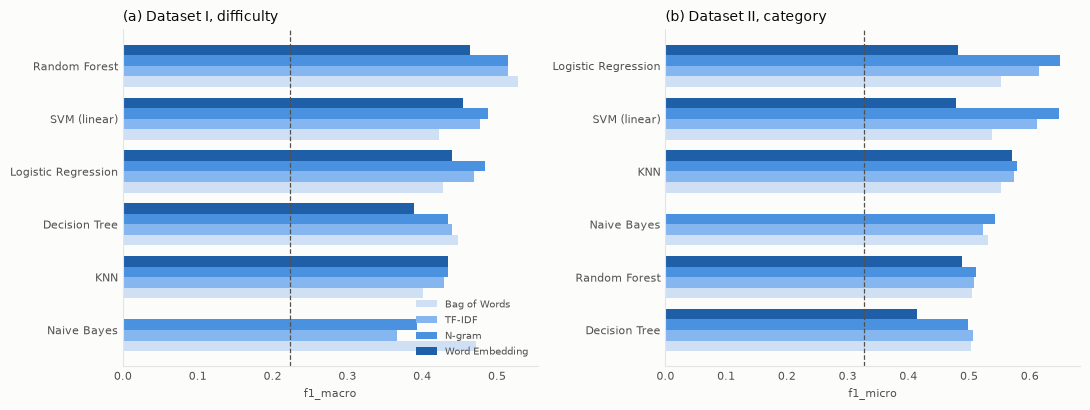

In [16]:
def rapikan(ax):
    ax.set_facecolor(SURFACE)
    for sisi in ("top", "right"):
        ax.spines[sisi].set_visible(False)
    for sisi in ("left", "bottom"):
        ax.spines[sisi].set_color(GARIS)
    ax.tick_params(colors=TEKS_SEKUNDER, length=0, labelsize=8)


WARNA = {"Bag of Words": "#cfe0f5", "TF-IDF": "#86b6ef",
         "N-gram": "#4a92e0", "Word Embedding": "#1f5fa8"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=SURFACE)
for ax, (hasil, kolom, judul, garis) in zip(axes, [
        (hasil1, "f1_macro", "(a) Dataset I, difficulty", baseline1["f1_macro"]),
        (hasil2, "f1_micro", "(b) Dataset II, category", baseline2["f1_micro"])]):
    pivot = hasil.pivot(index="algorithm", columns="representation", values=kolom)
    pivot = pivot.reindex(columns=list(WARNA)).sort_values("TF-IDF", na_position="first")
    posisi = np.arange(len(pivot))
    lebar = 0.2
    for i, rep in enumerate(WARNA):
        ax.barh(posisi + (i - 1.5) * lebar, pivot[rep].fillna(0), height=lebar,
                color=WARNA[rep], label=rep if judul.startswith("(a)") else "")
    ax.axvline(garis, color=TEKS_SEKUNDER, linewidth=0.9, linestyle="dashed")
    ax.set_yticks(posisi, pivot.index, fontsize=8)
    ax.set_title(judul, fontsize=10, color=TEKS_UTAMA, loc="left")
    ax.set_xlabel(kolom, fontsize=8, color=TEKS_SEKUNDER)
    rapikan(ax)
axes[0].legend(frameon=False, fontsize=7.5, loc="lower right", labelcolor=TEKS_SEKUNDER)
plt.tight_layout()
plt.savefig(GAMBAR / "fig_perbandingan.png", dpi=300, bbox_inches="tight")
plt.show()

**Penjelasan.** Empat warna mewakili empat representasi, garis putus putus adalah baseline. Panel kiri
memakai macro F1 karena targetnya single-label, panel kanan memakai micro F1 yang lazim
dipakai pada multi-label. Urutan batang memudahkan membaca representasi mana yang menang
pada hampir semua algoritma.

## Confusion Matrix Dataset I

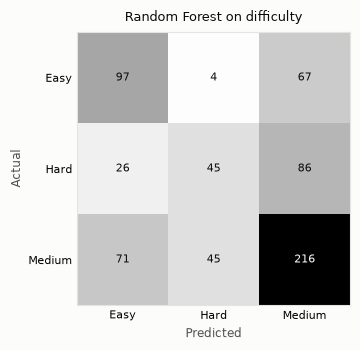

In [17]:
fig, ax = plt.subplots(figsize=(4.2, 3.6), facecolor=SURFACE)
ax.imshow(cm1, cmap="Greys", vmin=0, vmax=cm1.max())
ax.set_xticks(range(len(kelas1)), kelas1, fontsize=8)
ax.set_yticks(range(len(kelas1)), kelas1, fontsize=8)
ambang = cm1.max() / 2
for i in range(len(kelas1)):
    for j in range(len(kelas1)):
        ax.text(j, i, cm1[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm1[i, j] > ambang else TEKS_UTAMA)
ax.set_xlabel("Predicted", fontsize=8.5, color=TEKS_SEKUNDER)
ax.set_ylabel("Actual", fontsize=8.5, color=TEKS_SEKUNDER)
ax.set_title(f"{juara1['algorithm']} on difficulty", fontsize=9, color=TEKS_UTAMA, pad=8)
ax.tick_params(length=0)
for sisi in ax.spines.values():
    sisi.set_color(GARIS)
plt.tight_layout()
plt.savefig(GAMBAR / "fig_cm_dataset1.png", dpi=300, bbox_inches="tight")
plt.show()

**Penjelasan.** Baris adalah kelas sebenarnya dan kolom kelas tebakan, jadi angka di diagonal berarti
benar. Arah kesalahan lebih bermakna daripada jumlahnya, karena menunjukkan pasangan
kelas mana yang batasnya tidak tegas di ruang fitur.

## Word Cloud

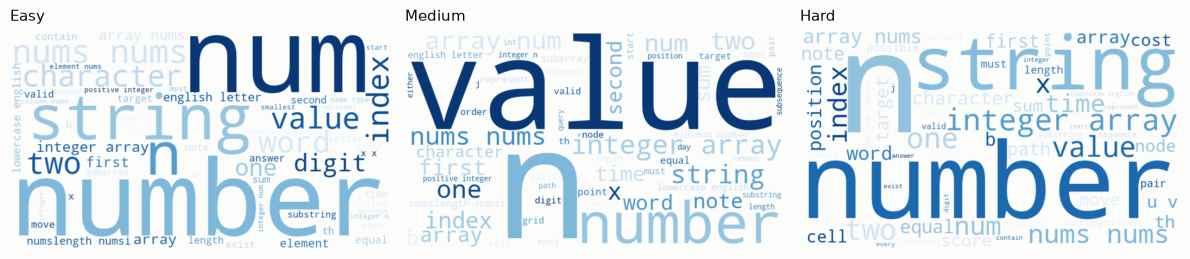

In [18]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), facecolor=SURFACE)
for ax, kelas in zip(axes, ["Easy", "Medium", "Hard"]):
    teks_kelas = " ".join(ds1.loc[ds1["Difficulty"] == kelas, "clean"])
    wc = WordCloud(width=700, height=400, background_color=SURFACE,
                   colormap="Blues_r", max_words=60, random_state=SEED).generate(teks_kelas)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(kelas, fontsize=11, color=TEKS_UTAMA, loc="left", pad=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(GAMBAR / "fig_wordcloud.png", dpi=300, bbox_inches="tight")
plt.show()

**Penjelasan.** Word cloud memperlihatkan kata yang paling sering muncul di tiap tingkat kesulitan.
Kemiripan ketiga gambar ini justru temuannya: kosakata ketiga tingkat kesulitan hampir
sama, yang menjelaskan kenapa menebak tingkat kesulitan dari teks saja sulit.

## Ringkasan Angka

In [19]:
ringkas = {
    "dataset1_soal": len(ds1),
    "dataset1_kelas": y1.nunique(),
    "dataset2_soal": len(ds2),
    "dataset2_label": len(LABEL),
    "dataset2_rata_label": round(float(Y2.sum(axis=1).mean()), 2),
    "total_token": len(token),
    "kata_unik": len(set(token)),
    "panjang_sebelum": round(ds1["Description"].str.len().mean()),
    "panjang_sesudah": round(ds1["clean"].str.len().mean()),
    "kosakata_w2v": len(kosakata),
    "dimensi_embedding": DIMENSI,
    "cakupan_token": round(100 * dikenali / len(token), 1),
    "kombinasi_dataset1": len(hasil1),
    "kombinasi_dataset2": len(hasil2),
    "terbaik_dataset1": f"{juara1['algorithm']} + {juara1['representation']}",
    "f1_macro_dataset1": round(juara1["f1_macro"], 3),
    "acc_dataset1": round(juara1["accuracy"], 3),
    "baseline_f1_dataset1": round(baseline1["f1_macro"], 3),
    "terbaik_dataset2": f"{juara2['algorithm']} + {juara2['representation']}",
    "f1_micro_dataset2": round(juara2["f1_micro"], 3),
    "f1_macro_dataset2": round(juara2["f1_macro"], 3),
    "hamming_dataset2": round(juara2["hamming_loss"], 3),
    "baseline_f1_micro_dataset2": round(baseline2["f1_micro"], 3),
}
pd.Series(ringkas).to_csv(HASIL / "ringkasan_angka.csv", header=False)
for k, v in ringkas.items():
    print(f"  {k:<28} {v}")

  dataset1_soal                3284
  dataset1_kelas               3
  dataset2_soal                3094
  dataset2_label               23
  dataset2_rata_label          2.85
  total_token                  275745
  kata_unik                    11257
  panjang_sebelum              1222
  panjang_sesudah              566
  kosakata_w2v                 3780
  dimensi_embedding            100
  cakupan_token                95.4
  kombinasi_dataset1           23
  kombinasi_dataset2           23
  terbaik_dataset1             Random Forest + Bag of Words
  f1_macro_dataset1            0.528
  acc_dataset1                 0.565
  baseline_f1_dataset1         0.224
  terbaik_dataset2             Logistic Regression + N-gram
  f1_micro_dataset2            0.65
  f1_macro_dataset2            0.551
  hamming_dataset2             0.085
  baseline_f1_micro_dataset2   0.327


**Penjelasan.** Setiap angka yang dikutip di paper dikumpulkan ke satu berkas, supaya kalau ada angka di
paper yang tidak ada di sini berarti angka itu tidak punya sumber dan harus dicek ulang.